In [1]:
from replicator_dynamics import *
# set seeds for reproducibility
# Fixed seed for script setup
SEED = 42
set_seed(SEED)

# Defining the synthetic city

In [2]:
modes = ['car', 'bus', 'active']

# Create a synthetic city of 10km x 10km with 50 nodes
G_city = create_multimodal_spatial(
    n=50, 
    radius=0.3, 
    modes=modes, 
    city_size_km=10.0,
    speeds_kmh={'car': 40.0, 'bus': 20.0, 'active': 12.0}
)

# Define the M matrix for cross-modal congestion impacts 
# M[impacted_mode][impacting_mode] represents how congestion in one mode affects travel times in another mode.
M_matrix_base = {
    'active': {'active': 0.01, 'bus': 0.005, 'car': 0.005},
    'bus':    {'active': 0.20, 'bus': 1.00,  'car': 0.90},
    'car':    {'active': 0.20, 'bus': 0.90,  'car': 2.00}
}

# Inspect a random edge to verify physical distances and times
sample_edge = list(G_city.edges())[0]
u, v = sample_edge
edge_data = G_city[u][v]

print(f"Synthetic City Graph generated with {G_city.number_of_nodes()} nodes.")
print(f"Sample Edge ({u} -> {v}):")
print(f"  - Length: {edge_data['length_km']:.3f} km")
print("  - Baseline Travel Times (B_a,m in minutes):")
for mode, time_min in edge_data['B'].items():
    print(f"    * {mode.capitalize()}: {time_min:.2f} min")

Synthetic City Graph generated with 50 nodes.
Sample Edge (0 -> 3):
  - Length: 2.602 km
  - Baseline Travel Times (B_a,m in minutes):
    * Car: 3.90 min
    * Bus: 7.81 min
    * Active: 13.01 min


# Single OD, Single Mode

In [3]:
print("--- Running Test Case 1 (Single OD, Single Mode on Spatial Graph) ---")

# 1. Extract node IDs from the spatial graph
nodes_list = list(G_city.nodes())
orig_node = nodes_list[0]
dest_node = nodes_list[-1]

one_mode = ['car']

# 2. Assign valid node IDs instead of coordinate tuples
od_pairs_1 = [{'orig': orig_node, 'dest': dest_node, 'demand': 1000, 'rho': 0.01}]

# M_matrix definition
one_mode_matrix = {'car': {'car': 0.005}} 

# 3. Initialize and run simulation
sim1 = ReplicatorDynamicsSimulator(G_city, od_pairs_1, one_mode, one_mode_matrix, num_paths=3)
sim1.run_simulation(steps=200, dt=1.0)

print(f"Simulation 1 completed. Final Global Fitness: {sim1.history_fitness[-1]:.2f}")
print(f"Final Path Flow Distribution: {np.round(sim1.history_x[-1], 1)}\n")

--- Running Test Case 1 (Single OD, Single Mode on Spatial Graph) ---
Simulation 1 completed. Final Global Fitness: 38.76
Final Path Flow Distribution: [473.6 293.9 232.6]



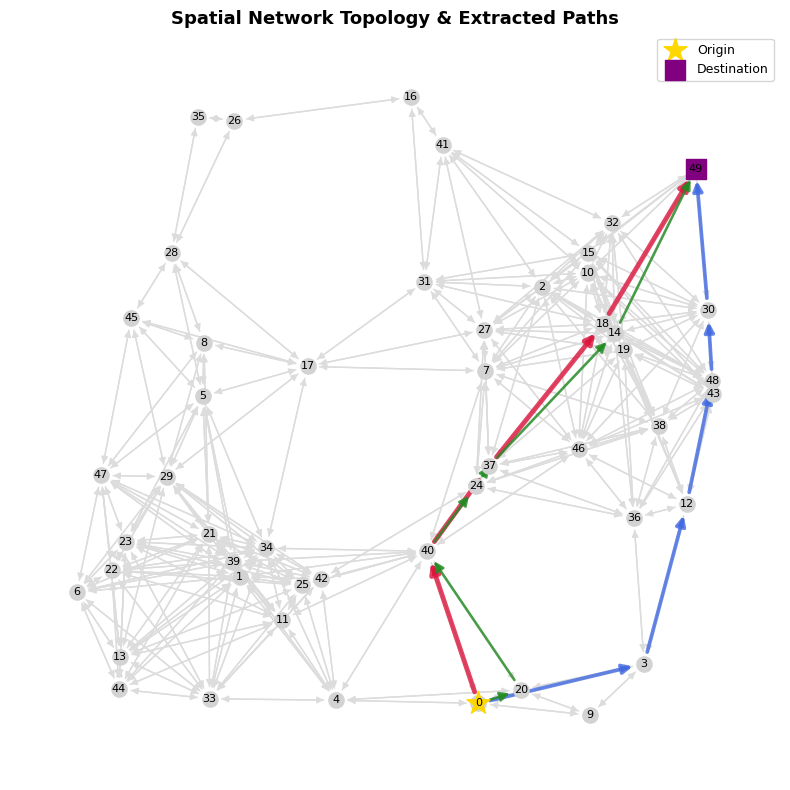

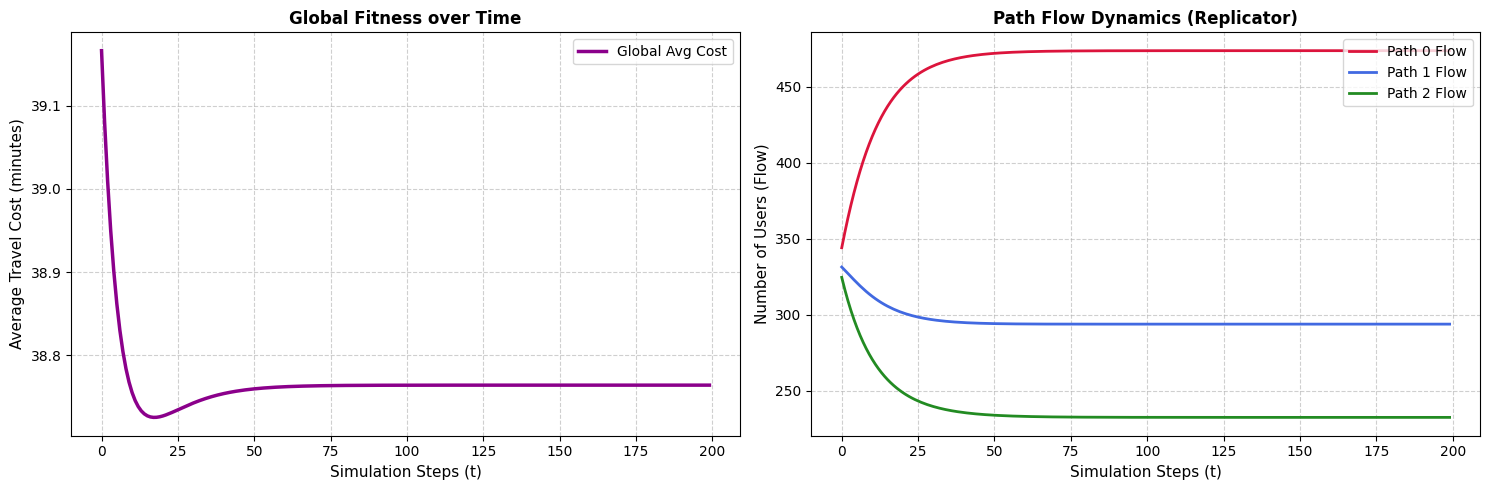

In [4]:
# ==========================================
# VISUALIZATION FOR TEST CASE 1 (SPATIAL / GENERIC GRAPH)
# ==========================================

# Extract spatial node coordinates from graph attributes
pos = nx.get_node_attributes(G_city, 'pos')

# Get origin and destination node IDs for OD pair 0
orig_node = sim1.od_pairs[0]['orig']
dest_node = sim1.od_pairs[0]['dest']

# --- Plot 1: Graph Topology and Generated Paths ---
plt.figure(figsize=(8, 8))

# Draw the background physical network
nx.draw_networkx_nodes(G_city, pos, node_color='lightgray', node_size=120)
nx.draw_networkx_labels(G_city, pos, font_size=8, font_color='black')
nx.draw_networkx_edges(G_city, pos, edgelist=G_city.edges(), edge_color='gainsboro', width=1, arrows=True, arrowsize=10)

# Highlight Origin (Gold Star) and Destination (Purple Square)
nx.draw_networkx_nodes(G_city, pos, nodelist=[orig_node], node_color='gold', node_shape='*', node_size=300, label='Origin')
nx.draw_networkx_nodes(G_city, pos, nodelist=[dest_node], node_color='purple', node_shape='s', node_size=200, label='Destination')

# Colors used to distinguish paths
path_colors = ['crimson', 'royalblue', 'forestgreen']

# Highlight each calculated path for the single mode
for idx, path_meta in enumerate(sim1.paths_info):
    # Convert path edge indices back to node pairs
    edge_indices = path_meta['edges']
    path_edges = [sim1.edges_list[e_idx] for e_idx in edge_indices]
    
    # Draw path edges on top of the physical network topology
    nx.draw_networkx_edges(
        G_city, pos, 
        edgelist=path_edges, 
        edge_color=path_colors[idx % len(path_colors)], 
        width=3.5 - (idx * 0.8), # Decreasing line width to reveal overlapping segments
        alpha=0.8,
        arrows=True,
        arrowsize=14,
        label=f"Path {path_meta['r_id']} ({path_meta['mode']})"
    )

plt.title("Spatial Network Topology & Extracted Paths", fontsize=13, fontweight='bold')
plt.legend(loc='best', fontsize=9)
plt.axis('off')
plt.tight_layout()
plt.show()


# --- Plot 2: Metrics Evolution (Fitness & Path Flows) ---
history_x = np.array(sim1.history_x)
history_fitness = np.array(sim1.history_fitness)
steps = len(history_fitness)
time_axis = np.arange(steps)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Subplot A: Global Fitness (Average Travel Cost in minutes)
ax1.plot(time_axis, history_fitness, color='darkmagenta', linewidth=2.5, label='Global Avg Cost')
ax1.set_title("Global Fitness over Time", fontsize=12, fontweight='bold')
ax1.set_xlabel("Simulation Steps (t)", fontsize=11)
ax1.set_ylabel("Average Travel Cost (minutes)", fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper right', fontsize=10)

# Subplot B: Path Flow Dynamics
for r_idx in range(sim1.num_total_paths):
    ax2.plot(
        time_axis, 
        history_x[:, r_idx], 
        color=path_colors[r_idx % len(path_colors)], 
        linewidth=2, 
        label=f"Path {r_idx} Flow"
    )

ax2.set_title("Path Flow Dynamics (Replicator)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Simulation Steps (t)", fontsize=11)
ax2.set_ylabel("Number of Users (Flow)", fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='upper right', fontsize=10) # Fixed explicitly specifying ax2

plt.tight_layout()
plt.show()

# Many ODs, single mode

In [5]:
# ------------------------------------------
# TEST CASE 2: Multiple ODs, Single Mode (Auto) on Spatial Graph G_city
# ------------------------------------------
import numpy as np
import networkx as nx
from replicator_dynamics import ReplicatorDynamicsSimulator

print("--- Running Test Case 2 (Multiple ODs, Single Mode on Spatial Graph) ---")

# Helper function to find the nearest node in G_city to given spatial coordinates (x, y) in km
def get_nearest_node(G: nx.DiGraph, target_coords: tuple):
    pos_dict = nx.get_node_attributes(G, 'pos')
    target_vec = np.array(target_coords)
    return min(
        pos_dict.keys(), 
        key=lambda node: np.linalg.norm(np.array(pos_dict[node]) - target_vec)
    )

# 1. Define single available mode
modes_2 = ['car']

# 2. Extract city spatial boundaries from G_city node coordinates
pos_coords = list(nx.get_node_attributes(G_city, 'pos').values())
max_x = max(c[0] for c in pos_coords)
max_y = max(c[1] for c in pos_coords)

# 3. Define multiple intersecting OD pairs using spatial positions in kilometer scale
# OD 0: Top-Left to Bottom-Right diagonal
orig_0 = get_nearest_node(G_city, (0.0, max_y))
dest_0 = get_nearest_node(G_city, (max_x, 0.0))

# OD 1: Bottom-Left to Top-Right diagonal (intersects OD 0)
orig_1 = get_nearest_node(G_city, (0.0, 0.0))
dest_1 = get_nearest_node(G_city, (max_x, max_y))

# OD 2: Middle-Left to Middle-Right (horizontal flow cutting across both diagonals)
orig_2 = get_nearest_node(G_city, (0.0, max_y / 2.0))
dest_2 = get_nearest_node(G_city, (max_x, max_y / 2.0))

od_pairs_2 = [
    {'orig': orig_0, 'dest': dest_0, 'demand': 1200, 'rho': 0.01}, # OD 0
    {'orig': orig_1, 'dest': dest_1, 'demand': 800,  'rho': 0.01}, # OD 1
    {'orig': orig_2, 'dest': dest_2, 'demand': 1500, 'rho': 0.01}  # OD 2
]

# 4. Define cost matrix for intra-modal congestion (car impacts car)
M_matrix_2 = {'car': {'car': 0.005}} 

# 5. Initialize and run simulation on G_city
sim2 = ReplicatorDynamicsSimulator(G_city, od_pairs_2, modes_2, M_matrix_2, num_paths=3)
sim2.run_simulation(steps=250, dt=1.0)

print(f"Simulation 2 completed. Final Global Fitness (Avg Travel Cost): {sim2.history_fitness[-1]:.2f} min\n")

# 6. Print final path flow distribution per OD pair
for od_id, od in enumerate(od_pairs_2):
    # Filter paths corresponding to this specific OD pair
    od_paths = [p for p in sim2.paths_info if p['od_id'] == od_id]
    path_indices = [p['r_id'] for p in od_paths]
    
    # Extract final path flows from simulation history
    final_flows = np.round(sim2.history_x[-1][path_indices], 1)
    print(f"OD {od_id} (Node {od['orig']} -> Node {od['dest']}) | Total Demand: {od['demand']}")
    for i, p_flow in enumerate(final_flows):
        print(f"  -> Path {path_indices[i]} Flow: {p_flow} users")
    print("-" * 50)

--- Running Test Case 2 (Multiple ODs, Single Mode on Spatial Graph) ---
Simulation 2 completed. Final Global Fitness (Avg Travel Cost): 49.32 min

OD 0 (Node 35 -> Node 3) | Total Demand: 1200
  -> Path 0 Flow: 422.7 users
  -> Path 1 Flow: 511.6 users
  -> Path 2 Flow: 265.7 users
--------------------------------------------------
OD 1 (Node 44 -> Node 49) | Total Demand: 800
  -> Path 3 Flow: 321.7 users
  -> Path 4 Flow: 242.1 users
  -> Path 5 Flow: 236.2 users
--------------------------------------------------
OD 2 (Node 47 -> Node 43) | Total Demand: 1500
  -> Path 6 Flow: 677.9 users
  -> Path 7 Flow: 512.3 users
  -> Path 8 Flow: 309.8 users
--------------------------------------------------


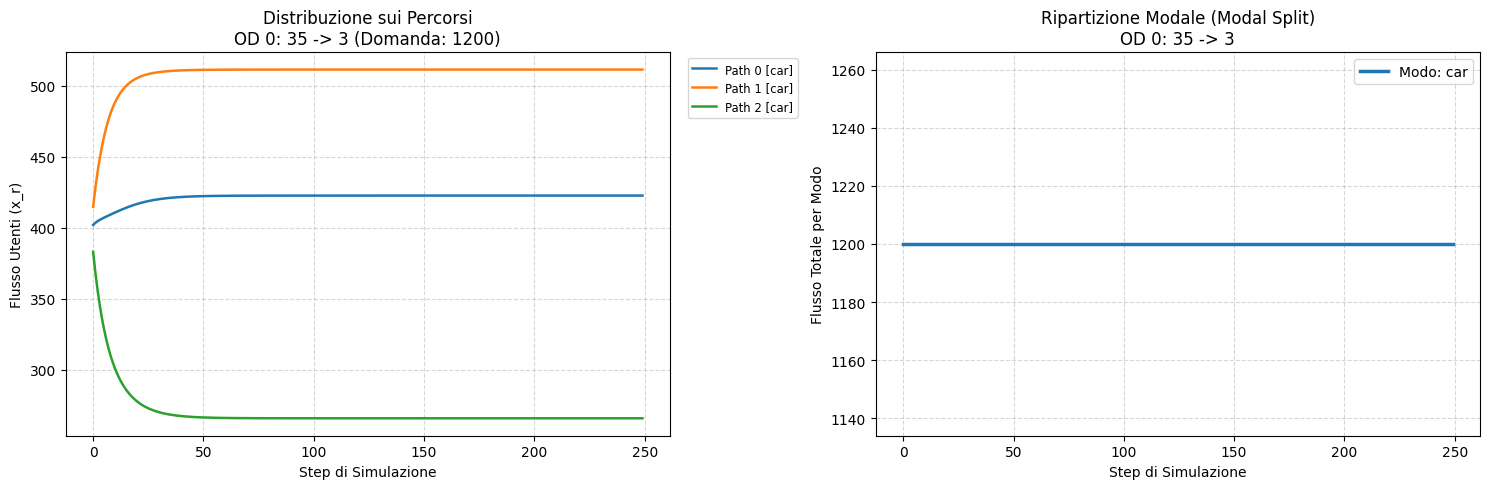

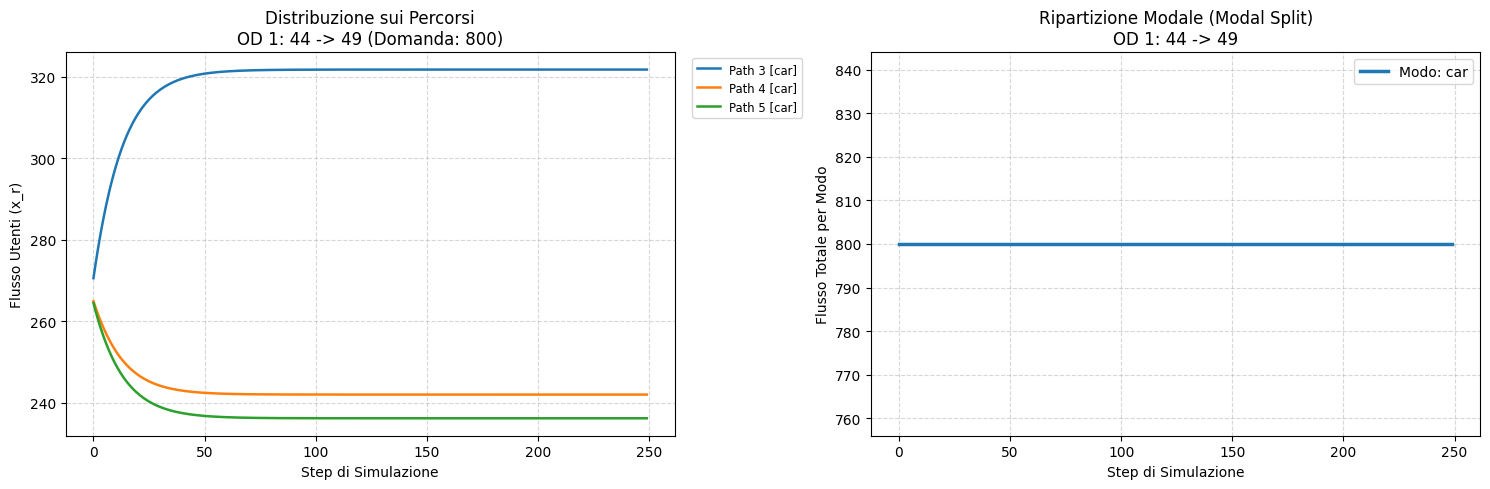

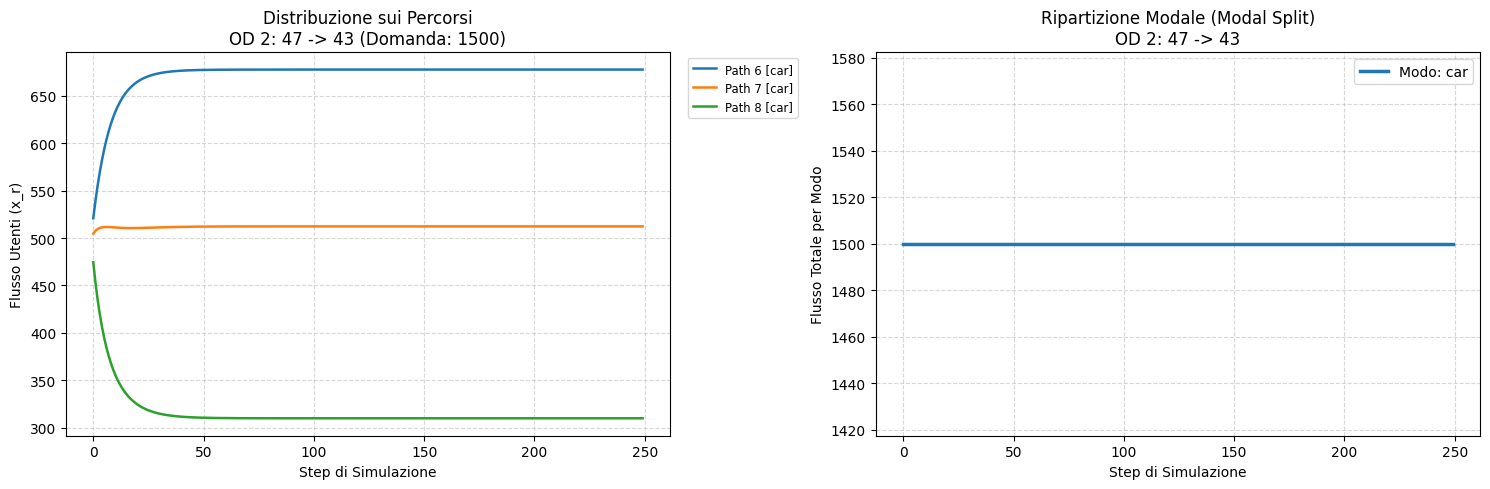

In [6]:
plot_od_evolution(sim2, od_id=0)
plot_od_evolution(sim2, od_id=1)
plot_od_evolution(sim2, od_id=2)

# Single OD, many modes

In [7]:
# ------------------------------------------
# TEST CASE 3: Single OD, Many Modes on Spatial Graph G_city
# ------------------------------------------
import numpy as np
import networkx as nx
from replicator_dynamics import ReplicatorDynamicsSimulator

print("--- Running Test Case 3 (Single OD, Many Modes on Spatial Graph) ---")

# 1. Define available transportation modes
modes_3 = ['car', 'bus', 'active']

# 2. Select valid origin and destination nodes from G_city
nodes_list = list(G_city.nodes())
orig_node = nodes_list[0]
dest_node = nodes_list[-1]

# 3. Define the single OD pair
total_demand = 1000
od_pairs_3 = [{'orig': orig_node, 'dest': dest_node, 'demand': total_demand, 'rho': 0.02}]

# 4. Define cross-modal congestion impact matrix M

# Apply scaling factor k to the congestion impact matrix
k = 0.1
M_matrix_3 = {
    mode1: {mode2: k * M_matrix_base[mode1][mode2] for mode2 in modes_3} 
    for mode1 in modes_3
}

# 5. Initialize and run the replicator dynamics simulator on G_city
sim3 = ReplicatorDynamicsSimulator(G_city, od_pairs_3, modes_3, M_matrix_3, num_paths=3)
sim3.run_simulation(steps=250, dt=1.0)

print(f"Simulation 3 completed. Final Global Fitness (Avg Travel Cost): {sim3.history_fitness[-1]:.2f} min\n")

# ------------------------------------------
# POST-SIMULATION: PERCENTAGE OF UTILIZATION
# ------------------------------------------
print("--- Final Utilization Percentages ---")

# Retrieve final path flow distribution vector x
final_flows = sim3.history_x[-1]

mode_totals = {mode: 0.0 for mode in modes_3}

# Print path-specific percentages using simulator metadata
for p in sim3.paths_info:
    r_id = p['r_id']
    mode = p['mode']
    flow = final_flows[r_id]
    percentage = (flow / total_demand) * 100
    
    mode_totals[mode] += percentage
    print(f"Mode: {mode.ljust(6)} | Path {r_id:>2} | Flow: {flow:>6.1f} users | Share: {percentage:>5.1f}%")

print("\n--- Modal Split (Total by Mode) ---")
for mode, pct in mode_totals.items():
    print(f"{mode.capitalize():<6}: {pct:.1f}%")

--- Running Test Case 3 (Single OD, Many Modes on Spatial Graph) ---
Simulation 3 completed. Final Global Fitness (Avg Travel Cost): 101.09 min

--- Final Utilization Percentages ---
Mode: car    | Path  0 | Flow:    0.0 users | Share:   0.0%
Mode: car    | Path  1 | Flow:    0.0 users | Share:   0.0%
Mode: car    | Path  2 | Flow:    0.0 users | Share:   0.0%
Mode: bus    | Path  3 | Flow:    0.0 users | Share:   0.0%
Mode: bus    | Path  4 | Flow:   76.5 users | Share:   7.7%
Mode: bus    | Path  5 | Flow:   62.5 users | Share:   6.3%
Mode: active | Path  6 | Flow:  861.0 users | Share:  86.1%
Mode: active | Path  7 | Flow:    0.0 users | Share:   0.0%
Mode: active | Path  8 | Flow:    0.0 users | Share:   0.0%

--- Modal Split (Total by Mode) ---
Car   : 0.0%
Bus   : 13.9%
Active: 86.1%


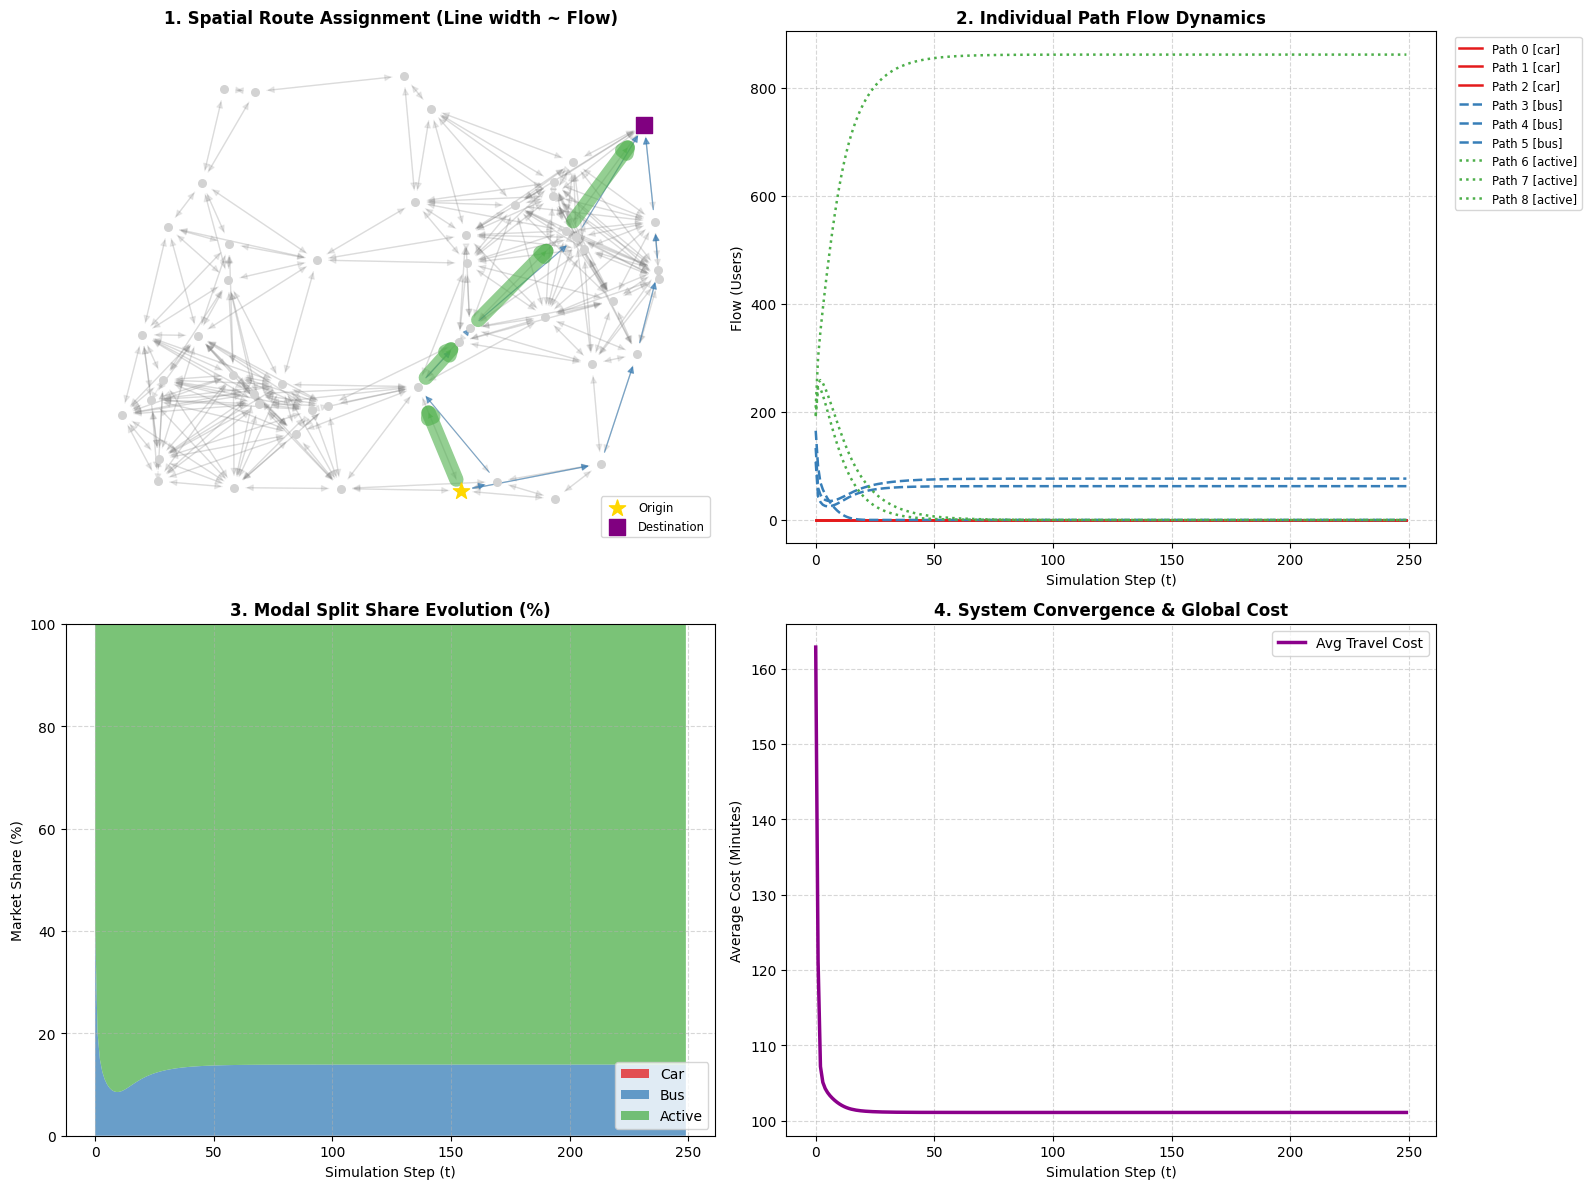

In [8]:
# ==========================================
# MULTIMODAL SIMULATION DASHBOARD (TEST 3)

# Extract data arrays from simulation history
history_x = np.array(sim3.history_x)
history_fitness = np.array(sim3.history_fitness)
steps_arr = np.arange(len(history_fitness))

total_demand = sim3.od_pairs[0]['demand']
orig_node = sim3.od_pairs[0]['orig']
dest_node = sim3.od_pairs[0]['dest']
pos = nx.get_node_attributes(G_city, 'pos')

# Setup color scheme for modes
mode_colors = {'car': '#e41a1c', 'bus': '#377eb8', 'active': '#4daf4a'} # Red, Blue, Green

# Create 2x2 Subplot Layout
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# ------------------------------------------------------------------
# PANEL 1 (Top-Left): Spatial Path Network on G_city
# ------------------------------------------------------------------
ax1 = axes[0, 0]

# Draw background network topology
nx.draw_networkx_nodes(G_city, pos, node_size=30, node_color='lightgray', ax=ax1)
nx.draw_networkx_edges(G_city, pos, alpha=0.15, edge_color='gray', ax=ax1)

# Highlight Origin and Destination nodes
nx.draw_networkx_nodes(G_city, pos, nodelist=[orig_node], node_size=150, node_color='gold', node_shape='*', label='Origin', ax=ax1)
nx.draw_networkx_nodes(G_city, pos, nodelist=[dest_node], node_size=120, node_color='purple', node_shape='s', label='Destination', ax=ax1)

# Overlay non-zero flow paths with line width proportional to final volume
final_flows = history_x[-1]
for p in sim3.paths_info:
    r_id = p['r_id']
    mode = p['mode']
    flow = final_flows[r_id]
    
    # Plot only paths carrying at least 0.5% of total demand
    if flow > (total_demand * 0.005):
        path_edges = [sim3.edges_list[e_idx] for e_idx in p['edges']]
        lw = (flow / total_demand) * 12.0
        
        nx.draw_networkx_edges(
            G_city, pos,
            edgelist=path_edges,
            edge_color=mode_colors[mode],
            width=lw,
            alpha=0.6,
            ax=ax1
        )

ax1.set_title("1. Spatial Route Assignment (Line width ~ Flow)", fontsize=12, fontweight='bold')
ax1.axis('off')
ax1.legend(loc='lower right', fontsize='small')

# ------------------------------------------------------------------
# PANEL 2 (Top-Right): Path Flow Dynamics Over Time
# ------------------------------------------------------------------
ax2 = axes[0, 1]

for p in sim3.paths_info:
    r_id = p['r_id']
    mode = p['mode']
    flow_history = history_x[:, r_id]
    
    # Use solid line for car, dashed for bus, dotted for active
    ls = '-' if mode == 'car' else ('--' if mode == 'bus' else ':')
    
    ax2.plot(
        steps_arr, 
        flow_history, 
        color=mode_colors[mode], 
        linestyle=ls, 
        linewidth=1.8, 
        label=f"Path {r_id} [{mode}]"
    )

ax2.set_title("2. Individual Path Flow Dynamics", fontsize=12, fontweight='bold')
ax2.set_xlabel("Simulation Step (t)")
ax2.set_ylabel("Flow (Users)")
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize='small')

# ------------------------------------------------------------------
# PANEL 3 (Bottom-Left): Modal Split Evolution (Stacked Area)
# ------------------------------------------------------------------
ax3 = axes[1, 0]

# Calculate total flow per mode at each simulation step
mode_flows_time = {mode: np.zeros(len(steps_arr)) for mode in sim3.modes}
for p in sim3.paths_info:
    mode_flows_time[p['mode']] += history_x[:, p['r_id']]

# Convert to percentage shares
mode_shares_time = [
    (mode_flows_time[m] / total_demand) * 100.0 for m in sim3.modes
]

ax3.stackplot(
    steps_arr, 
    mode_shares_time, 
    labels=[m.capitalize() for m in sim3.modes],
    colors=[mode_colors[m] for m in sim3.modes],
    alpha=0.75
)

ax3.set_title("3. Modal Split Share Evolution (%)", fontsize=12, fontweight='bold')
ax3.set_xlabel("Simulation Step (t)")
ax3.set_ylabel("Market Share (%)")
ax3.set_ylim(0, 100)
ax3.grid(True, linestyle='--', alpha=0.5)
ax3.legend(loc='lower right')

# ------------------------------------------------------------------
# PANEL 4 (Bottom-Right): System Average Cost (Global Fitness)
# ------------------------------------------------------------------
ax4 = axes[1, 1]

ax4.plot(steps_arr, history_fitness, color='darkmagenta', linewidth=2.5, label='Avg Travel Cost')
ax4.set_title("4. System Convergence & Global Cost", fontsize=12, fontweight='bold')
ax4.set_xlabel("Simulation Step (t)")
ax4.set_ylabel("Average Cost (Minutes)")
ax4.grid(True, linestyle='--', alpha=0.5)
ax4.legend(loc='upper right')

plt.tight_layout()
plt.show()

# Many ODs, many modes

In [14]:
# ------------------------------------------
# FINAL TEST CASE: Multiple ODs, Multiple Modes on Spatial Graph G_city

print("--- Running Final Test Case (Multi-OD, Multi-Mode on Spatial Graph) ---")

# 1. Define available transportation modes
modes = ['active', 'bus', 'car']

# 2. Helper function to map grid coordinates (0..8, 0..8) to nearest real nodes in G_city
pos_coords = list(nx.get_node_attributes(G_city, 'pos').values())
max_x = max(c[0] for c in pos_coords)
max_y = max(c[1] for c in pos_coords)

def map_grid_to_spatial_node(G: nx.DiGraph, grid_tuple: tuple, grid_size: int = 8):
    """
    Maps a (gx, gy) grid coordinate tuple (from 0 to grid_size) to the nearest 
    physical node in G_city based on kilometer spatial coordinates.
    """
    gx, gy = grid_tuple
    
    # Map grid index [0, 8] to physical city size [0, max_x] and [0, max_y]
    target_x = (gx / float(grid_size)) * max_x
    target_y = (gy / float(grid_size)) * max_y
    target_vec = np.array([target_x, target_y])
    
    pos_dict = nx.get_node_attributes(G, 'pos')
    return min(
        pos_dict.keys(), 
        key=lambda node: np.linalg.norm(np.array(pos_dict[node]) - target_vec)
    )

# 3. Define raw grid OD structure (9x9 grid layout)
raw_od_pairs = [
    # 1. RADIAL INFLOWS (Suburbs -> CBD at grid (4,4))
    {'orig': (0, 0), 'dest': (4, 4), 'demand': 2500, 'rho': 0.020},  # SW -> CBD
    {'orig': (8, 0), 'dest': (4, 4), 'demand': 2200, 'rho': 0.020},  # SE -> CBD
    {'orig': (0, 8), 'dest': (4, 4), 'demand': 2000, 'rho': 0.018},  # NW -> CBD
    {'orig': (8, 8), 'dest': (4, 4), 'demand': 2400, 'rho': 0.020},  # NE -> CBD
    {'orig': (4, 0), 'dest': (4, 4), 'demand': 1800, 'rho': 0.016},  # South -> CBD
    {'orig': (0, 4), 'dest': (4, 4), 'demand': 1700, 'rho': 0.016},  # West -> CBD

    # 2. REVERSE COMMUTING (CBD (4,4) -> Suburbs)
    {'orig': (4, 4), 'dest': (8, 8), 'demand': 1200, 'rho': 0.015},  # CBD -> NE
    {'orig': (4, 4), 'dest': (0, 0), 'demand': 1100, 'rho': 0.015},  # CBD -> SW

    # 3. CROSS-TOWN ARTERIAL CORRIDORS
    {'orig': (0, 4), 'dest': (8, 4), 'demand': 1600, 'rho': 0.017},  # West-East Axis
    {'orig': (4, 0), 'dest': (4, 8), 'demand': 1500, 'rho': 0.017},  # South-North Axis
    {'orig': (0, 0), 'dest': (8, 8), 'demand': 1400, 'rho': 0.015},  # SW -> NE Diagonal
    {'orig': (8, 0), 'dest': (0, 8), 'demand': 1300, 'rho': 0.014},  # SE -> NW Diagonal

    # 4. RING ROADS / PERIPHERY CORRIDORS (Bypassing CBD)
    {'orig': (0, 2), 'dest': (2, 8), 'demand': 950,  'rho': 0.012},  # NW Ring Road
    {'orig': (6, 0), 'dest': (8, 6), 'demand': 850,  'rho': 0.012},  # SE Ring Road
    {'orig': (2, 0), 'dest': (8, 2), 'demand': 1000, 'rho': 0.013},  # South Periphery

    # 5. LOCALIZED SHORT-DISTANCE TRIPS
    {'orig': (1, 1), 'dest': (3, 3), 'demand': 700,  'rho': 0.010},  # SW Neighborhood
    {'orig': (5, 5), 'dest': (7, 7), 'demand': 750,  'rho': 0.010}   # NE Neighborhood
]

# 4. Map raw OD grid tuples into valid G_city integer node IDs
od_pairs = []
for od in raw_od_pairs:
    node_orig = map_grid_to_spatial_node(G_city, od['orig'], grid_size=8)
    node_dest = map_grid_to_spatial_node(G_city, od['dest'], grid_size=8)
    
    # Avoid zero-length routes where origin maps to the same node as destination
    if node_orig != node_dest:
        od_pairs.append({
            'orig': node_orig,
            'dest': node_dest,
            'demand': od['demand'],
            'rho': od['rho']
        })

--- Running Final Test Case (Multi-OD, Multi-Mode on Spatial Graph) ---


In [15]:
# 5. Define cross-modal marginal cost interaction matrix
M_matrix_base = {
    'active': {'active': 0.01, 'bus': 0.005, 'car': 0.005},
    'bus':    {'active': 0.20, 'bus': 1.00,  'car': 0.90},
    'car':    {'active': 0.20, 'bus': 0.90,  'car': 2.00}
}

# Apply global scaling factor k
k = 0.1  
M_matrix = {
    mode1: {mode2: k * M_matrix_base[mode1][mode2] for mode2 in modes} 
    for mode1 in modes
}

# 6. Initialize and run simulation on G_city
sim2 = ReplicatorDynamicsSimulator(G_city, od_pairs, modes, M_matrix, num_paths=3)
sim2.run_simulation(steps=2000, dt=0.1)

print(f"Simulation completed successfully.")
print(f"  - Initial Global Fitness (Avg Travel Cost): {sim2.history_fitness[0]:.2f} min")
print(f"  - Final Global Fitness (Avg Travel Cost):   {sim2.history_fitness[-1]:.2f} min")
print(f"  - Flow History Shape (steps, total paths): {np.array(sim2.history_x).shape}")

Simulation completed successfully.
  - Initial Global Fitness (Avg Travel Cost): 256.44 min
  - Final Global Fitness (Avg Travel Cost):   115.03 min
  - Flow History Shape (steps, total paths): (2000, 153)


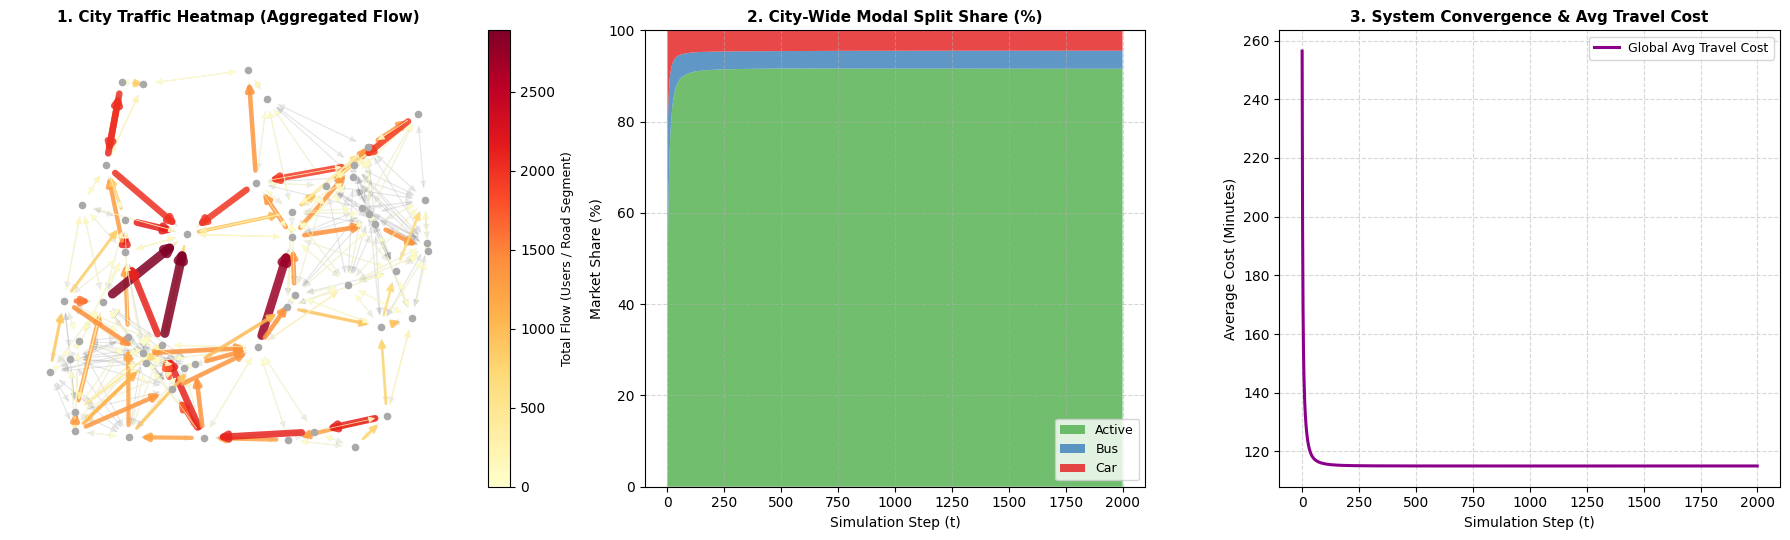

In [16]:
# ==============================================================================
# LIGHTWEIGHT MULTI-OD MULTIMODAL DASHBOARD (AGGREGATED EDGE TRAFFIC & METRICS)

# Extract simulation history arrays
history_x = np.array(sim2.history_x)
history_fitness = np.array(sim2.history_fitness)
steps_arr = np.arange(len(history_fitness))
final_flows = history_x[-1]

# Spatial positions of nodes in G_city (in kilometers)
pos = nx.get_node_attributes(G_city, 'pos')
total_city_demand = sum(od['demand'] for od in sim2.od_pairs)

# ------------------------------------------------------------------------------
# 1. CALCULATE AGGREGATED TRAFFIC VOLUME PER EDGE (Summed across all paths)
# ------------------------------------------------------------------------------
num_edges = len(sim2.edges_list)
edge_volumes = np.zeros(num_edges)

# Aggregate final user flows passing through each physical edge
for path in sim2.paths_info:
    r_id = path['r_id']
    flow = final_flows[r_id]
    for edge_idx in path['edges']:
        edge_volumes[edge_idx] += flow

# Setup 1x3 Subplot Dashboard
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# ------------------------------------------------------------------------------
# PANEL 1: City-Wide Congestion & Road Network Volume Heatmap
# ------------------------------------------------------------------------------
ax1 = axes[0]

# Draw background network topology in light gray
nx.draw_networkx_nodes(G_city, pos, node_size=20, node_color='darkgray', ax=ax1)
nx.draw_networkx_edges(G_city, pos, alpha=0.1, edge_color='gray', width=0.8, ax=ax1)

# Filter edges carrying actual traffic (volume > 0)
active_edge_indices = np.where(edge_volumes > 0)[0]
active_edges = [sim2.edges_list[idx] for idx in active_edge_indices]
active_volumes = edge_volumes[active_edge_indices]

# Scale line widths and apply color mapping based on edge volume
max_vol = max(active_volumes) if len(active_volumes) > 0 else 1.0
widths = (active_volumes / max_vol) * 6.0 + 0.5

# Draw loaded roads colored by volume intensity (YlOrRd colormap)
edges_drawn = nx.draw_networkx_edges(
    G_city, pos,
    edgelist=active_edges,
    edge_color=active_volumes,
    edge_cmap=plt.cm.YlOrRd,
    width=widths,
    alpha=0.85,
    ax=ax1
)

# Add colorbar for traffic volume intensity
sm = plt.cm.ScalarMappable(cmap=plt.cm.YlOrRd, norm=plt.Normalize(vmin=0, vmax=max_vol))
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax1, fraction=0.046, pad=0.04)
cbar.set_label("Total Flow (Users / Road Segment)", fontsize=9)

ax1.set_title("1. City Traffic Heatmap (Aggregated Flow)", fontsize=11, fontweight='bold')
ax1.axis('off')

# ------------------------------------------------------------------------------
# PANEL 2: Global City-Wide Modal Split Evolution (Stacked Area Chart)
# ------------------------------------------------------------------------------
ax2 = axes[1]
mode_colors = {'car': '#e41a1c', 'bus': '#377eb8', 'active': '#4daf4a'}

# Compute total flow per transportation mode at each step
mode_flows_time = {mode: np.zeros(len(steps_arr)) for mode in sim2.modes}
for path in sim2.paths_info:
    mode_flows_time[path['mode']] += history_x[:, path['r_id']]

# Convert to global market share percentage (%)
mode_shares_time = [
    (mode_flows_time[m] / total_city_demand) * 100.0 for m in sim2.modes
]

ax2.stackplot(
    steps_arr, 
    mode_shares_time, 
    labels=[m.capitalize() for m in sim2.modes],
    colors=[mode_colors[m] for m in sim2.modes],
    alpha=0.8
)

ax2.set_title("2. City-Wide Modal Split Share (%)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Simulation Step (t)", fontsize=10)
ax2.set_ylabel("Market Share (%)", fontsize=10)
ax2.set_ylim(0, 100)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='lower right', fontsize=9)

# ------------------------------------------------------------------------------
# PANEL 3: System Cost Convergence (Global Fitness)
# ------------------------------------------------------------------------------
ax3 = axes[2]

ax3.plot(steps_arr, history_fitness, color='darkmagenta', linewidth=2.2, label='Global Avg Travel Cost')
ax3.set_title("3. System Convergence & Avg Travel Cost", fontsize=11, fontweight='bold')
ax3.set_xlabel("Simulation Step (t)", fontsize=10)
ax3.set_ylabel("Average Cost (Minutes)", fontsize=10)
ax3.grid(True, linestyle='--', alpha=0.5)
ax3.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()